# Exploratory Analysis on the Stack Overflow Developer Survey 2026

## Importing libraries and other settings to save charts, enable scrolling on the results, and displaying options

In [188]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import scipy.stats as stats
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import OneHotEncoder 
from pathlib import Path

In [189]:
plt.style.use('ggplot')

In [190]:
eda_charts_dir = Path("/workspaces/ai_datascience_stackoverflow_2026/charts/EDA")
eda_charts_dir.mkdir(parents=True, exist_ok=True)

def save_eda_chart(fig, filename, dpi = 300):
    path = eda_charts_dir / f"{filename}.png"
    fig.savefig(path, dpi=dpi, bbox_inches='tight')
    print(f"Saved EDA chart: {path}")

In [191]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

In [192]:
from IPython.display import HTML, display

def scroll(df, height=400):
    """Show a DataFrame in a fixed-height scrollable box."""
    display(HTML(f'<div style="max-height:{height}px; overflow:auto">{df.to_html()}</div>'))

In [193]:
import matplotlib.font_manager as fm

text_properties = {
    'fontsize': 9,      # Increase font size
    'fontweight': 'semibold' # Set font weight
}

# Customize wedge (slice) properties (for borders)
wedge_properties = {
    'linewidth': 0.4,        # Set border width
    'edgecolor': 'black' # Set border color
}

## Data Exploratory

In [194]:
eda_data = pd.read_csv("/workspaces/ai_datascience_stackoverflow_2026/data/raw/survey_results_public.csv", index_col=0)
eda_data.head(5)

/tmp/ipykernel_1714/1806460769.py:1: DtypeWarning: Columns (154: AICost, 155: AICostPrompt) have mixed types. Specify dtype option on import or set low_memory=False.
  eda_data = pd.read_csv("/workspaces/ai_datascience_stackoverflow_2026/data/raw/survey_results_public.csv", index_col=0)


,Age,CodeMain,Education,Employment,EmploymentAddl,ICorPM,WorkSetting,LearnCode,LearnCodeHow,LearnAI,LearnAIHow,YearsCode,WorkExp,Role,RoleFunctions,OrgSize,TechBudget,PurchasePower,Industry,JobSat,JobSatComplacent,JobEase,JobEaseAI_1,JobEaseAI_2,JobEaseAI_3,JobEaseAI_4,JobEaseAI_5,JobEaseAI_6,JobEaseAI_7,JobEaseAI_8,JobEaseAI_9,JobEaseAI_10,JobDifficulty,JobDifficultyAI_1,JobDifficultyAI_2,JobDifficultyAI_3,JobDifficultyAI_4,JobDifficultyAI_5,JobDifficultyAI_6,JobDifficultyAI_7,JobDifficultyAI_8,JobDifficultyAI_9,JobDifficultyAI_10,ToolCount,Gender,Country,Currency,Compensation,TechDropDown,LanguagesHaveWorkedWith,LanguagesWantToWorkWith,LanguagesUsedAI,LanguagesAdmired,CodeTestHaveWorkedWith,CodeTestWantToWorkWith,CodeTestAdmired,DatabasesHaveWorkedWith,DatabasesWantToWorkWith,DatabasesAdmired,CloudPlatHaveWorkedWith,CloudPlatWantToWorkWith,CloudPlatAdmired,WebFrameworkHaveWorkedWith,WebFrameworkWantToWorkWith,WebFrameworkAdmired,DevIDEHaveWorkedWith,DevIDEWantToWorkWith,DevIDEAdmired,CommPlatHaveWorkedWith,CommPlatWantToWorkWith,CommPlatAdmired,LLMHaveWorkedWith,LLMWantToWorkWith,LLMUsedInAgents,LLMAdmired,KnowMgmtHaveWorkedWith,KnowMgmtWantToWorkWith,KnowMgmtUsedInAgenticWorkflows,KnowMgmtAdmired,EntSearchHaveWorkedWith,EntSearchWantToWorkWith,EntSearchUsedInAgenticWorkflows,EntSearchAdmired,SecOpsHaveWorkedWith,SecOpsWantToWorkWith,SecOpsUsedInAgenticWorkflows,SecOpsAdmired,BuildTool,BuildToolAI,Disruption,SOAccount,SOYears,SOChange,Answers,AnswersTrust,CommunityType,CommunityGap,CommunitySkills,AISelect,AIFreq_1,AIFreq_2,AIFreq_3,AIFreq_4,AIDaily,AISentiment,AIComplex,AITrust,AIWorkCurrentlyUse,AIWorkExpectMore,AIWorkExpectLess,AIWorkDoNotPlanToUse,AIWorkNotInWorkflow,AIWorkNext,AIToolCount,AIToolSwitch,AIImpact_1,AIImpact_2,AIImpact_3,AIImpact_4,AIImpact_5,AIImpact_6,AIImpact_7,AISat_1,AISat_2,AISat_3,AISat_4,AISat_5,AISat_6,AISat_7,AIRetain,AIMemHaveWorkedWith,AIMemWantToUseNext6Months,AIMemAdmired,AIOrchHaveWorkedWith,AIOrchWantToUseNext6Months,AIOrchAdmired,AIObsHaveWorkedWith,AIObsWantToUseNext6Months,AIObsAdmired,AICodeAgentHaveWorkedWith,AICodeAgentWantToUseNext6Months,AICodeAgentAdmired,AINoCodeHaveWorkedWith,AINoCodeWantToUseNext6Months,AINoCodeAdmired,AIAutomateHaveWorkedWith,AIAutomateWantToUseNext6Months,AIAutomateAdmired,AIUse,AIAvoid,AITry,AIAdopt,AIToken,AICost,AICostPrompt,KnowledgeQ,KnowledgeAcc_1,KnowledgeAcc_2,KnowledgeAcc_3,KnowledgeAcc_4,KnowledgeAcc_5,KnowledgeAcc_6,KnowledgeAcc_7,KnowledgeAcc_8,KnowledgeAcc_9,KnowledgeAcc_10,KnowledgeAcc_11,KnowledgeAcc_12,KnowledgeAcc_13,KnowledgeAcc_14,KnowledgeAcc_15,KnowledgeTime_1,KnowledgeTime_2,KnowledgeTime_3,KnowledgeTime_4,KnowledgeTime_5,KnowledgeTime_6,KnowledgeTime_7,KnowledgeTime_8,KnowledgeTime_9,KnowledgeTime_10,KnowledgeTime_11,KnowledgeTime_12,KnowledgeTime_13,KnowledgeTime_14,KnowledgeTime_15,KnowledgeSource_1,KnowledgeSource_2,KnowledgeSource_3,KnowledgeSource_4,KnowledgeSource_5,KnowledgeSource_6,KnowledgeSource_7,KnowledgeSource_8,KnowledgeSource_9,KnowledgeSource_10,KnowledgeSource_11,KnowledgeSource_12,KnowledgeSource_13,KnowledgeSource_14,KnowledgeSource_15,KnowledgeSourceAI,KnowAgentDelegate,KnowledgeA,TrustReason,KnowAgentTrust,ContextSelect,ContextProblems,ContextFreq,ContextWork,ConvertedCompYearly
ResponseId,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,35-44 years old,I create code as a primary part of my job,"Master's degree (M.A., M.S., M.Eng., MBA, etc.)","Independent contractor, freelancer, or self-em...",None of the above,Individual contributor in a senior or staff-le...,"Hybrid (some remote, leans heavy to in-person)",Yes,AI codegen tools or AI-enabled apps,"Yes, on my own",Games or coding challenges,NaN,NaN,"Developer, back-end",Writing or updating documentation,Less than 20 employees,Increased,I make the final decision to purchase tools,Education,3.0,NaN,I’m not s

In [195]:
eda_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 30903 entries, 1 to 30903
Columns: 211 entries, Age to ConvertedCompYearly
dtypes: float64(14), str(197)
memory usage: 148.1 MB


In [196]:
eda_data.shape

(30903, 211)

In [197]:
eda_data.columns.to_list()

['Age',
 'CodeMain',
 'Education',
 'Employment',
 'EmploymentAddl',
 'ICorPM',
 'WorkSetting',
 'LearnCode',
 'LearnCodeHow',
 'LearnAI',
 'LearnAIHow',
 'YearsCode',
 'WorkExp',
 'Role',
 'RoleFunctions',
 'OrgSize',
 'TechBudget',
 'PurchasePower',
 'Industry',
 'JobSat',
 'JobSatComplacent',
 'JobEase',
 'JobEaseAI_1',
 'JobEaseAI_2',
 'JobEaseAI_3',
 'JobEaseAI_4',
 'JobEaseAI_5',
 'JobEaseAI_6',
 'JobEaseAI_7',
 'JobEaseAI_8',
 'JobEaseAI_9',
 'JobEaseAI_10',
 'JobDifficulty',
 'JobDifficultyAI_1',
 'JobDifficultyAI_2',
 'JobDifficultyAI_3',
 'JobDifficultyAI_4',
 'JobDifficultyAI_5',
 'JobDifficultyAI_6',
 'JobDifficultyAI_7',
 'JobDifficultyAI_8',
 'JobDifficultyAI_9',
 'JobDifficultyAI_10',
 'ToolCount',
 'Gender',
 'Country',
 'Currency',
 'Compensation',
 'TechDropDown',
 'LanguagesHaveWorkedWith',
 'LanguagesWantToWorkWith',
 'LanguagesUsedAI',
 'LanguagesAdmired',
 'CodeTestHaveWorkedWith',
 'CodeTestWantToWorkWith',
 'CodeTestAdmired',
 'DatabasesHaveWorkedWith',
 'Databa

In [198]:
eda_data.dtypes.value_counts()

str        197
float64     14
Name: count, dtype: int64

### Initial findings:

- A big dataset with 211 columns and over 30k records.
- 197 columns are `string` and 14 are `float` datatype.

In [199]:
scroll(eda_data.describe(include='all').T)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,30903,8,25-34 years old,9267,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CodeMain,30794,5,I create code as a primary part of my job,23234,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Education,30761,8,"Bachelor's degree (B.A., B.S., B.Eng., etc.)",12396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Employment,30903,6,Employed,20259,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EmploymentAddl,28099,173,None of the above,11297,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ICorPM,24749,4,Individual contributor,12568,NaN,NaN,NaN,NaN,NaN,NaN,NaN
WorkSetting,24602,5,Remote,8564,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LearnCode,29146,2,Yes,15169,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LearnCodeHow,14530,2060,AI codegen tools or AI-enabled apps,574,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LearnAI,28240,4,"Yes, both on my own and at work",11350,NaN,NaN,NaN,NaN,NaN,NaN,NaN


A glance at the unique values and top `string` values, plus their frequencies, gave me the idea of which features I should use in later parts of this project.
- Age is an important factor here, I expected the younger devs would takes the majority of the dataset. 
- Needs to keep eyes on AI features though, some of them I had used for the last year's dataset, but this year looks different a bit.
- `AIWorkCurrentlyUse` and `AIWorkExpectMore` is a new one, and it needs some text analysis, since the top value looks to be included with all of it column values.
- I should picked out ones that are ordinal at first, then worry about the nominal ones later.
- Some ordinal features are worth examining:
    - `KnowAgentTrust`
    - `AICostPrompt`
    - `AIUse`
    - `AIAvoid`
    - `AITry`
    - `AIRetain`
    - `AIToolCount`
- However, the primary AI features that I would continue using will be `AISelect`, `AIFreq` (this feature seems to have more sub-features this year), `AIDaily`, `AI Sentiment`, `AIComplex`, and `AITrust`.


In [200]:
missing = pd.DataFrame({
    "n_missing": eda_data.isnull().sum(),
    "pct_missing": (eda_data.isnull().mean() * 100).round(1)
}).sort_values("pct_missing", ascending=False)

scroll(missing)

,n_missing,pct_missing
JobEaseAI_7,30903,100.0
JobEaseAI_10,30903,100.0
JobEaseAI_9,30903,100.0
JobDifficultyAI_9,30903,100.0
JobDifficultyAI_10,30903,100.0
JobDifficultyAI_8,30903,100.0
KnowledgeTime_14,30810,99.7
KnowledgeSource_14,30814,99.7
KnowledgeAcc_14,30805,99.7
AIMemAdmired,30778,99.6


Identifying the proportion of missing values in each columns, and just as I expected, survey data seems to have lots of missing, empty, or null values. Surveyees can answer whatever they want, and I got to be really careful picking which to work with and how to clean it.

In [201]:
eda_data['Age'].value_counts(dropna=False).sort_index()

Age
18-24 years old       4944
25-34 years old       9267
35-44 years old       8522
45-54 years old       4198
55-64 years old       1829
65 years or older      822
Prefer not to say      352
Under 18 years old     969
Name: count, dtype: int64

Examining the distribution of devs' age range.

Saved EDA chart: /workspaces/ai_datascience_stackoverflow_2026/charts/EDA/age_distribution.png


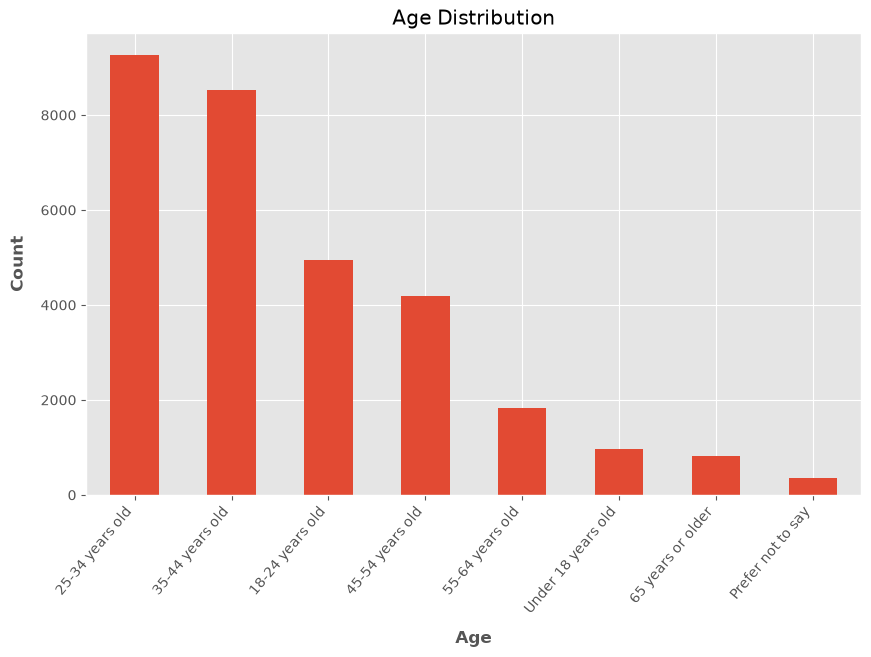

In [202]:
ax = eda_data['Age'].value_counts().plot(kind='bar', figsize=(10, 6), title='Age Distribution')

ax.set_xlabel('Age', fontsize=12, labelpad=10, fontweight='bold')
ax.set_ylabel('Count', fontsize=12, labelpad=10, fontweight='bold')

plt.xticks(rotation=50, ha="right")   # rotate x-axis labels
plt.yticks(rotation= 360)

save_eda_chart(ax.get_figure(), "age_distribution")

I might drop the `Prefer not to say` and `Under 18 years old`, to have a cleaner and more relevant dataset concentrating on the use of AI.

Saved EDA chart: /workspaces/ai_datascience_stackoverflow_2026/charts/EDA/workexp_distribution.png


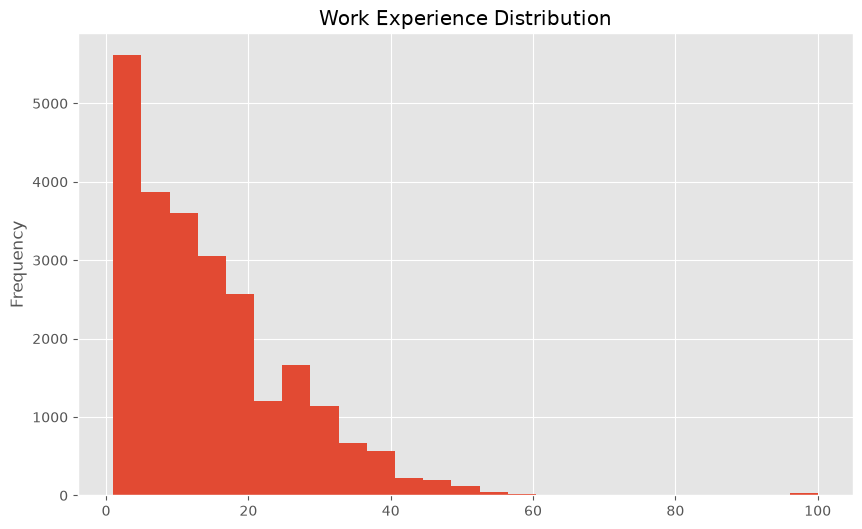

In [203]:
ax = eda_data['WorkExp'].plot(kind='hist', bins=25, figsize=(10, 6), title='Work Experience Distribution')

save_eda_chart(ax.get_figure(), "workexp_distribution")

There it is, some outlier out there, no one works from the 1926 and still alive today, not even to mention that coding in 1926! 

Still, I need to rethink on the range for `WorkExp` after filtering out a subset of columns, because there's no way I could know whether a 65 or 70 years old worker have been coding for over 40 years.

Saved EDA chart: /workspaces/ai_datascience_stackoverflow_2026/charts/EDA/codemain_distribution.png


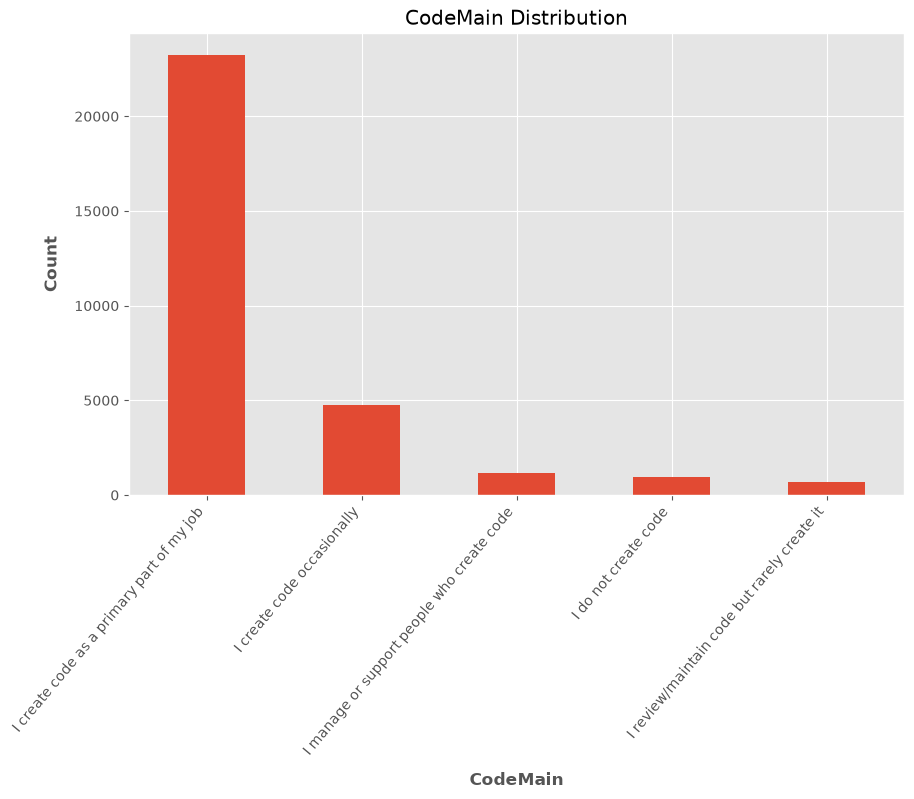

In [204]:
ax = eda_data['CodeMain'].value_counts().plot(kind='bar', figsize=(10, 6), title='CodeMain Distribution')

ax.set_xlabel('CodeMain', fontsize=12, labelpad=10, fontweight='bold')
ax.set_ylabel('Count', fontsize=12, labelpad=10, fontweight='bold')

plt.xticks(rotation=50, ha="right")   # rotate x-axis labels
plt.yticks(rotation= 360)

save_eda_chart(ax.get_figure(), "codemain_distribution")

I will definitely include this column `CodeMain` in some further projects. However, I'm not sure if it will be too relevant, more statistical correlations are needed to examine it along with other features.

Saved EDA chart: /workspaces/ai_datascience_stackoverflow_2026/charts/EDA/learncode_distribution.png


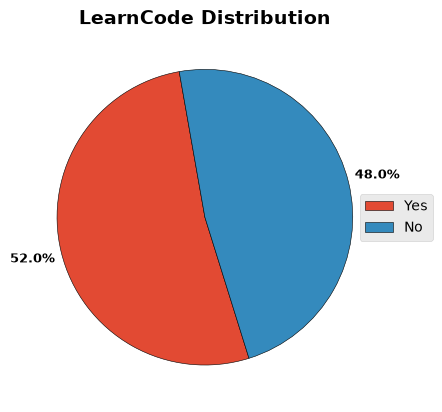

In [205]:
labels = eda_data['LearnCode'].value_counts().index
size = eda_data['LearnCode'].value_counts().values

plt.title('LearnCode Distribution', fontsize=14, fontweight='bold')
wedges, texts, autotexts = plt.pie(
    size, 
    autopct='%1.1f%%',
    pctdistance=1.2, 
    startangle=100, 
    wedgeprops=wedge_properties,
    textprops=text_properties
)

plt.legend(
    wedges, 
    labels,
    loc='center left',  
    bbox_to_anchor=(0.9, 0.5), 
    fontsize='medium'
)
save_eda_chart(ax.get_figure(), "learncode_distribution")

That is pretty equal, I'd include this too since it would be an important demographic feature representing coding and AI, but the latter EDA phase for this `LearnCode` would be important, since a subset data might have a different result.

Saved EDA chart: /workspaces/ai_datascience_stackoverflow_2026/charts/EDA/learnai_distribution.png


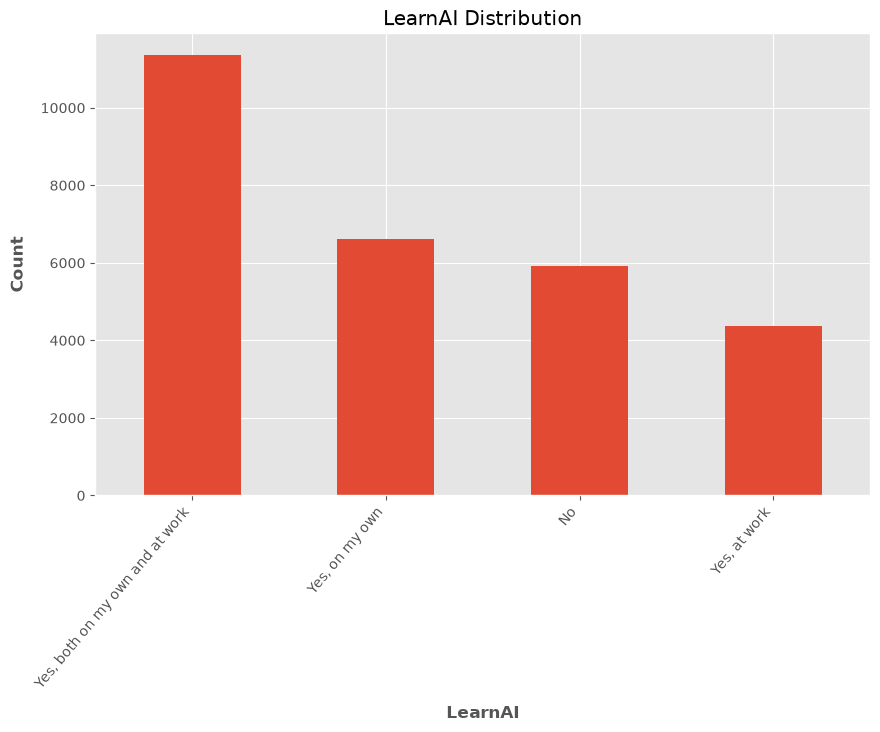

In [206]:
ax = eda_data['LearnAI'].value_counts().plot(kind='bar', figsize=(10, 6), title='LearnAI Distribution')

ax.set_xlabel('LearnAI', fontsize=12, labelpad=10, fontweight='bold')
ax.set_ylabel('Count', fontsize=12, labelpad=10, fontweight='bold')

plt.xticks(rotation=50, ha="right")   # rotate x-axis labels
plt.yticks(rotation= 360)

save_eda_chart(ax.get_figure(), "learnai_distribution")

It appears that all 30k+ devs takes AI learning seriously, both on their own and at work, another important feature to include in further analytics. However, at this point, it occurs to me that rearranging the order is crucial when moving forward to the real analysis set.

Saved EDA chart: /workspaces/ai_datascience_stackoverflow_2026/charts/EDA/jobease_distribution.png


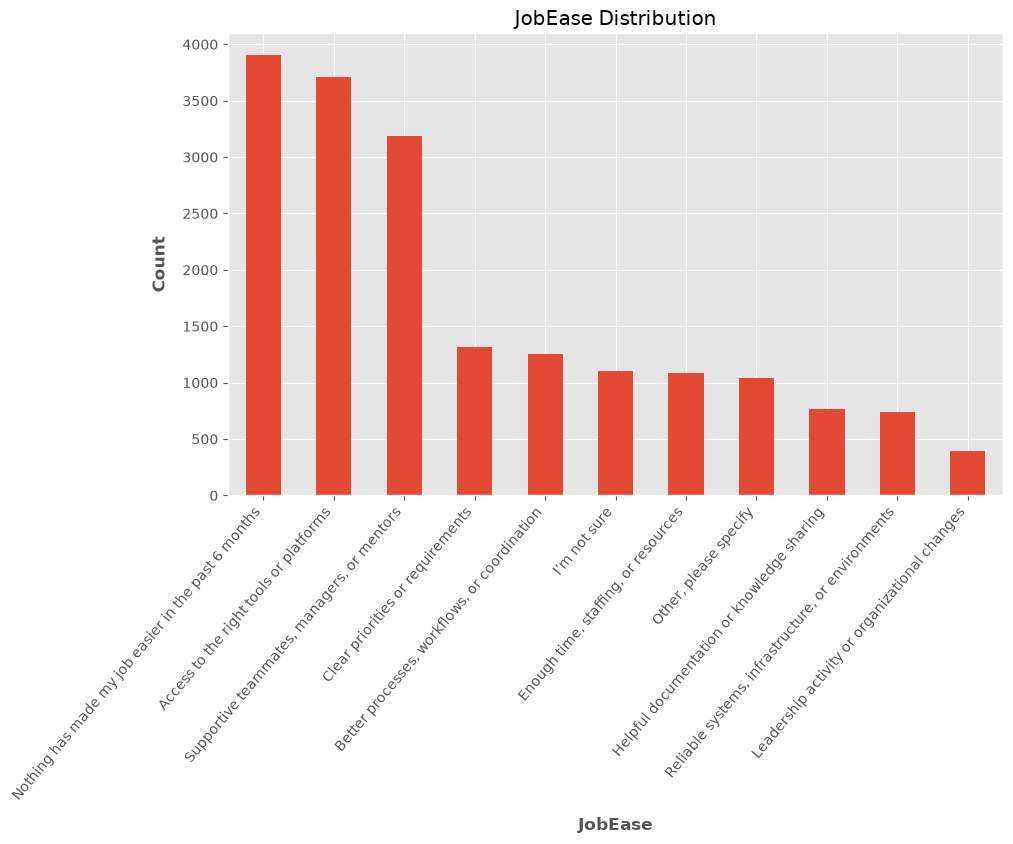

In [207]:
ax = eda_data['JobEase'].value_counts().plot(kind='bar', figsize=(10, 6), title='JobEase Distribution')

ax.set_xlabel('JobEase', fontsize=12, labelpad=10, fontweight='bold')
ax.set_ylabel('Count', fontsize=12, labelpad=10, fontweight='bold')

plt.xticks(rotation=50, ha="right")   # rotate x-axis labels
plt.yticks(rotation= 360)

save_eda_chart(ax.get_figure(), "jobease_distribution")

`JobEase` seems to be interesting when conducting a correlation with other features, different age, jobs, or other occupations, or even experience would have different correlation to look at with this feature.

## Correlation Analysis

Performing some correlation analysis, but to save myself some time and effort, this current section will not be arranging order for better visualization yet, as it will be for me to look through. When I have finalize he features that I am going to examine further, I will rearranging the order of the ordinal values so it will give better visualized result. 

In [208]:
codemain_learnai_table = pd.crosstab(eda_data['CodeMain'], eda_data['LearnAI'])
print("Contingency Table for CodeMain and LearnAI:")
codemain_learnai_table

Contingency Table for CodeMain and LearnAI:


LearnAI,No,"Yes, at work","Yes, both on my own and at work","Yes, on my own"
CodeMain,,,,
I create code as a primary part of my job,3877,3667,9466,4382
I create code occasionally,1436,349,1015,1511
I do not create code,380,49,83,297
I manage or support people who create code,119,171,553,222
I review/maintain code but rarely create it,97,116,226,170


Saved EDA chart: /workspaces/ai_datascience_stackoverflow_2026/charts/EDA/codemain_learnai_heatmap.png


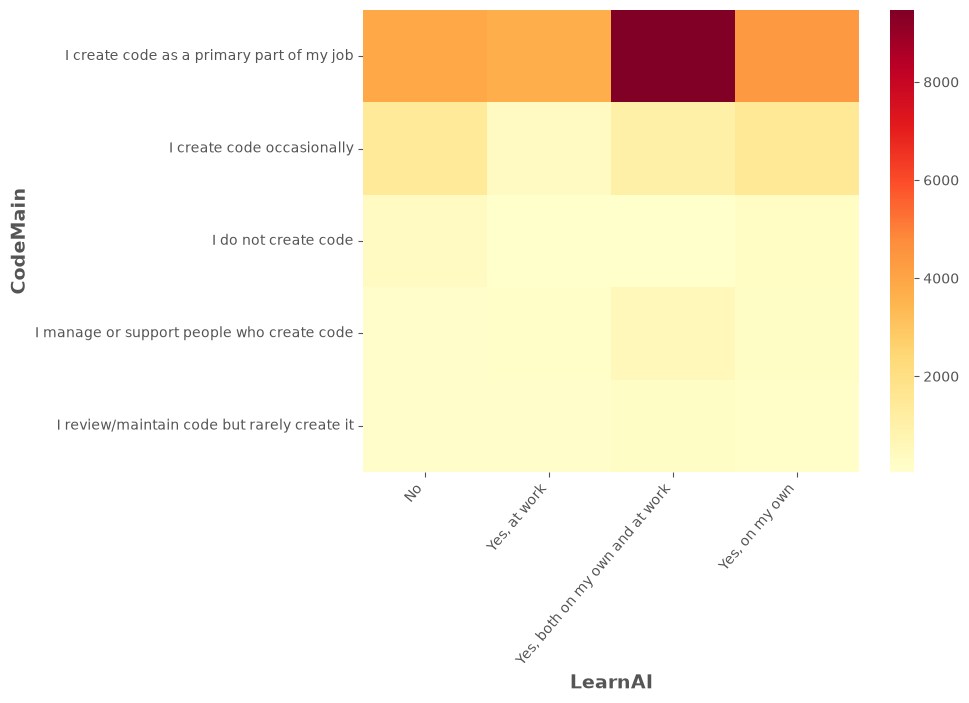

In [209]:

plt.figure(figsize=(8, 6))
sns.heatmap(codemain_learnai_table, annot=False, fmt="d", cmap="YlOrRd")

plt.ylabel("CodeMain", fontsize = 14, fontweight = 'bold')
plt.xlabel("LearnAI", fontsize = 14, fontweight = 'bold')

plt.xticks(rotation=50, ha="right")   # rotate x-axis labels
plt.yticks(rotation= 360)

save_eda_chart(plt.gcf(), "codemain_learnai_heatmap")
plt.show()
     

Contingency Table for Age and LearnAI:
LearnAI               No  Yes, at work  Yes, both on my own and at work  \
Age                                                                       
18-24 years old     1325           376                             1200   
25-34 years old     1618          1488                             3619   
35-44 years old     1184          1485                             3740   
45-54 years old      597           644                             1861   
55-64 years old      359           272                              675   
65 years or older    271            57                              130   
Prefer not to say    136            22                               65   
Under 18 years old   433            16                               60   

LearnAI             Yes, on my own  
Age                                 
18-24 years old               1404  
25-34 years old               1657  
35-44 years old               1501  
45-54 years old          

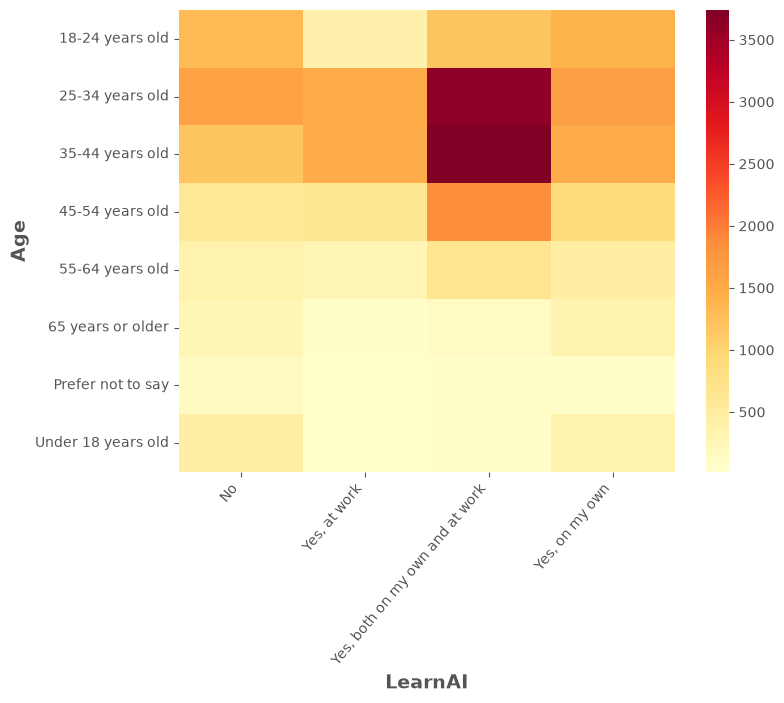

In [210]:
age_learnai_table = pd.crosstab(eda_data['Age'], eda_data['LearnAI'])
print("Contingency Table for Age and LearnAI:")
print(age_learnai_table)

plt.figure(figsize=(8, 6))
sns.heatmap(age_learnai_table, annot=False, fmt="d", cmap="YlOrRd")

plt.ylabel("Age", fontsize = 14, fontweight = 'bold')
plt.xlabel("LearnAI", fontsize = 14, fontweight = 'bold')

plt.xticks(rotation=50, ha="right")   # rotate x-axis labels
plt.yticks(rotation= 360)

save_eda_chart(plt.gcf(), "age_learnai_heatmap")
plt.show()

Contingency Table for Age and AIComplex:
AIComplex           Bad at handling complex tasks  \
Age                                                 
18-24 years old                               323   
25-34 years old                               729   
35-44 years old                               663   
45-54 years old                               349   
55-64 years old                               114   
65 years or older                              45   
Prefer not to say                              23   
Under 18 years old                             53   

AIComplex           Good, but not great at handling complex tasks  \
Age                                                                 
18-24 years old                                               639   
25-34 years old                                              1623   
35-44 years old                                              1700   
45-54 years old                                               905   
55-64 years ol

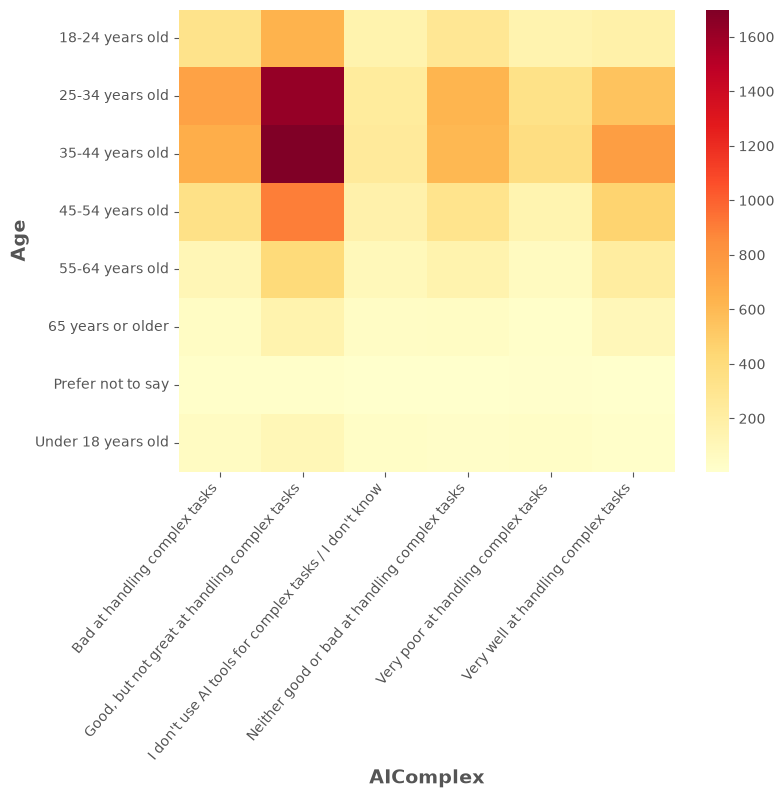

In [211]:
age_learnai_table = pd.crosstab(eda_data['Age'], eda_data['AIComplex'])
print("Contingency Table for Age and AIComplex:")
print(age_learnai_table)

plt.figure(figsize=(8, 6))
sns.heatmap(age_learnai_table, annot=False, fmt="d", cmap="YlOrRd")

plt.ylabel("Age", fontsize = 14, fontweight = 'bold')
plt.xlabel("AIComplex", fontsize = 14, fontweight = 'bold')

plt.xticks(rotation=50, ha="right")   # rotate x-axis labels
plt.yticks(rotation= 360)

save_eda_chart(plt.gcf(), "age_aicomplex_heatmap")
plt.show()

## Testing phase for the subset features

These are not the official finalized features that I am going to use for my first project using this survey data, but it is meant to be testing how these features would work or correlate with each other after filtering some unnescessary values out.

In [212]:
# --- Column groups ---
id_cols = ["Age", "Employment", "CodeMain", "Role", "OrgSize", "Industry"]
experience_cols = ["WorkExp", "YearsCode", "JobEase"]
ai_attitude_cols = ["AISentiment", "AIComplex", "AITrust"]
ai_usage_cols = ["AIDaily", "AIToolCount"]
ai_org_cols = ["LearnAI", "AIUse", "AIAvoid", "AITry"]
outcome_cols = ["JobSat"]

selected_cols = (
    ["Country"] + id_cols + experience_cols + ai_attitude_cols
    + ai_usage_cols  + ai_org_cols + outcome_cols
)

# Check that every column exists
missing_cols = [c for c in selected_cols if c not in eda_data.columns]
print("Missing columns:", missing_cols)

# --- Filter: US only, selected columns ---
us_data = (
    eda_data.loc[eda_data["Country"] == "United States of America", selected_cols]
    .drop(columns="Country")
    .copy()
)

print(f"US respondents: {len(us_data):,} of {len(eda_data):,}")
print(f"Columns kept: {us_data.shape[1]}")
print("\nUS respondents by age band:")
print(us_data["Age"].value_counts().sort_index())

Missing columns: []
US respondents: 4,755 of 30,903
Columns kept: 19

US respondents by age band:
Age
18-24 years old        444
25-34 years old       1097
35-44 years old       1332
45-54 years old        847
55-64 years old        515
65 years or older      303
Prefer not to say       75
Under 18 years old     142
Name: count, dtype: int64


In [213]:
eda_data['Employment'].value_counts(dropna=False).sort_index()

Employment
Employed                                                20259
I prefer not to say                                       549
Independent contractor, freelancer, or self-employed     4607
Not employed                                             1742
Retired                                                   607
Student                                                  3139
Name: count, dtype: int64

In [214]:
country_us = ['United States of America']
age_over_18 = ['18-24 years old', '25-34 years old', '35-44 years old', '45-54 years old', '55-64 years old', '65 years or older']
currently_employed = ['Employed', 'Independent contractor, freelancer, or self-employed', 'Student','Not Employed']

query_str = "Country == 'United States of America' and Age in @age_over_18 and Employment in @currently_employed"


filtered_eda_data = eda_data.query(query_str)[selected_cols]
filtered_eda_data.head(5).reset_index(drop=True)

,Country,Age,Employment,CodeMain,Role,OrgSize,Industry,WorkExp,YearsCode,JobEase,AISentiment,AIComplex,AITrust,AIDaily,AIToolCount,LearnAI,AIUse,AIAvoid,AITry,JobSat
0,United States of America,25-34 years old,Employed,I create code as a primary part of my job,Academic researcher,"10,000 or more employees",Scientific research,5.0,16.0,Helpful documentation or knowledge sharing,Somewhat unfavorable,Very poor at handling complex tasks,I do not trust it for most work tasks,NaN,1.0,"Yes, on my own",AI use is mostly optional and left up to indiv...,Concern over losing job skills or training an ...,Different teams choose their own tools or models,8.0
1,United States of America,45-54 years old,Employed,I create code as a primary part of my job,"Developer, full-stack",500 to 999 employees,Government,26.0,31.0,Access to the right tools or platforms,Somewhat favorable,"Good, but not great at handling complex tasks",I do not trust it for most work tasks,2-4 hours/day,2.0,"Yes, at work","Some teams actively encourage AI use, but prac...",Concern over losing job skills or training an ...,We use a few approved tools or models,9.0
2,United States of America,55-64 years old,Employed,I create code as a primary part of my job,"Developer, full-stack",Less than 20 employees,"IT services, consulting, systems integration, ...",40.0,46.0,Nothing has made my job easier in the past 6 m...,NaN,NaN,NaN,NaN,NaN,No,"Some teams actively encourage AI use, but prac...",Moral or ethical concerns,We mostly use one approved tool or model,7.0
3,United States of America,45-54 years old,Employed,I create code as a primary part of my job,"Architect, software or solutions",100 to 499 employees,"Retail, e-commerce, or consumer services",28.0,38.0,"Reliable systems, infrastructure, or environments",Very unfavorable,"Good, but not great at handling complex tasks","I trust it for many tasks, but not important w...",2-4 hours/day,4.0,"Yes, both on my own and at work","Some teams actively encourage AI use, but prac...",Concern over losing job skills or training an ...,We are trying multiple tools or models before ...,8.0
4,United States of America,25-34 years old,Employed,I create code as a primary part of my job,Applied scientist,"10,000 or more employees",Engineering services or applied R&D,10.0,16.0,Access to the right tools or platforms,Neutral,Neither good or bad at handling complex tasks,I trust it for low-risk work tasks only,NaN,2.0,"Yes, both on my own and at work",AI use is mostly optional and left up to indiv...,Issues with privacy or security,We use a few approved tools or models,6.0


In [215]:
filtered_eda_data.info()

<class 'pandas.DataFrame'>
Index: 3979 entries, 8 to 30863
Data columns (total 20 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Country      3979 non-null   str    
 1   Age          3979 non-null   str    
 2   Employment   3979 non-null   str    
 3   CodeMain     3971 non-null   str    
 4   Role         3958 non-null   str    
 5   OrgSize      3812 non-null   str    
 6   Industry     3793 non-null   str    
 7   WorkExp      3855 non-null   float64
 8   YearsCode    3877 non-null   float64
 9   JobEase      3784 non-null   str    
 10  AISentiment  2761 non-null   str    
 11  AIComplex    2761 non-null   str    
 12  AITrust      2760 non-null   str    
 13  AIDaily      2064 non-null   str    
 14  AIToolCount  2463 non-null   float64
 15  LearnAI      3970 non-null   str    
 16  AIUse        3027 non-null   str    
 17  AIAvoid      3074 non-null   str    
 18  AITry        2959 non-null   str    
 19  JobSat       3795 non

After processing and filtering out columns, values, the subset data has 3,979 entries and 20 columns. Further analysis will based on this subset.

Since I don't wanna work with any null values, let's get rid of all of the null values.

In [216]:
filtered_eda_data_cleaned = filtered_eda_data.dropna()
filtered_eda_data_cleaned.info()

<class 'pandas.DataFrame'>
Index: 1678 entries, 13 to 30772
Data columns (total 20 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Country      1678 non-null   str    
 1   Age          1678 non-null   str    
 2   Employment   1678 non-null   str    
 3   CodeMain     1678 non-null   str    
 4   Role         1678 non-null   str    
 5   OrgSize      1678 non-null   str    
 6   Industry     1678 non-null   str    
 7   WorkExp      1678 non-null   float64
 8   YearsCode    1678 non-null   float64
 9   JobEase      1678 non-null   str    
 10  AISentiment  1678 non-null   str    
 11  AIComplex    1678 non-null   str    
 12  AITrust      1678 non-null   str    
 13  AIDaily      1678 non-null   str    
 14  AIToolCount  1678 non-null   float64
 15  LearnAI      1678 non-null   str    
 16  AIUse        1678 non-null   str    
 17  AIAvoid      1678 non-null   str    
 18  AITry        1678 non-null   str    
 19  JobSat       1678 no

In [217]:
pattern = r"\bother\b|i don[’']?t know"

text_cols = filtered_eda_data_cleaned.select_dtypes(exclude="number").columns

mask = (
    filtered_eda_data_cleaned[text_cols]
      .apply(lambda col: col.str.contains(pattern, case=False, regex=True, na=False))
      .any(axis=1)
)

print(f"Before: {len(filtered_eda_data_cleaned)} rows")
print(f"Dropped: {mask.sum()} rows")

filtered_eda_data_cleaned = filtered_eda_data_cleaned.loc[~mask].copy()
print(f"After: {len(filtered_eda_data_cleaned)} rows")

Before: 1678 rows
Dropped: 353 rows
After: 1325 rows


### New Subset

Only half of the original subset, but this would be a start, since applying ML to a survey dataset might not particularly gives correct information at all, so it would be essential to start with a small sample.

1,678 records would do, but more cleaning and organizing are needed.

In [218]:
filtered_eda_data_cleaned.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Country,1325,1,United States of America,1325,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,1325,6,35-44 years old,456,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Employment,1325,3,Employed,1186,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CodeMain,1325,4,I create code as a primary part of my job,1151,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Role,1325,38,"Developer, full-stack",464,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OrgSize,1325,8,"10,000 or more employees",290,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Industry,1325,22,Software development,286,NaN,NaN,NaN,NaN,NaN,NaN,NaN
WorkExp,1325.0,NaN,NaN,NaN,18.384906,11.480303,1.0,10.0,16.0,26.0,67.0
YearsCode,1325.0,NaN,NaN,NaN,21.955472,11.853536,1.0,12.0,20.0,30.0,63.0
JobEase,1325,10,Access to the right tools or platforms,367,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### The Role Column

I need to put some attention to this column first, since it has over 41 distinct values.

In [219]:
filtered_eda_data_cleaned["Role"].value_counts(dropna=False).sort_index()

Role
AI/ML engineer                                                                23
Academic researcher                                                           13
Applied scientist                                                             15
Architect, software or solutions                                             127
Cloud infrastructure engineer                                                 16
Cybersecurity or InfoSec professional                                          8
Data engineer                                                                 30
Data or business analyst                                                      18
Data scientist                                                                23
Database administrator or engineer                                             3
DevOps engineer or professional                                               20
Developer advocate or developer relations professional                         7
Developer, AI apps or p

Right, so the majority of them are quite distinct, except for some differences in Developers and Engineers.

Different Developers and Engineers work in different fields, but for the sake of this dataset, I am thinking about reducing the complexity of it. 

First off, putting all Developer and Engineer together. But one thing I need to keep in mind is explaining this in the other notebook project when I finalized the cleaning process for this subset.

In [220]:
#filtered_eda_data_cleaned["role_cat"] = np.where(
    #filtered_eda_data_cleaned["Role"].str.contains("developer", case=False, na=False), "Developer", 
    #np.where(filtered_eda_data_cleaned["Role"].str.contains("engineer", case=False, na=False), "Engineer",
    #np.where(filtered_eda_data_cleaned["Role"].str.contains("data", case=False, na=False), "Data Analyst/Scientist",
    #np.where(filtered_eda_data_cleaned["Role"].str.contains(["executive", "manager", "founder", "marketing"], case=False, na=False), "Leadership & Business",
    #np.where(filtered_eda_data_cleaned["Role"].str.contains("Architect", case=False, na=False), "Architecture",
    #np.where(filtered_eda_data_cleaned["Role"].str.contains(["researcher", "applied", "educator", "student"], case=False, na=False), "Research & Education",
    #np.where(filtered_eda_data_cleaned["Role"].str.contains(["Cybersecurity", "System", "technical", "UX"], case=False, na=False), "Specialist / Support",
    #"Other/Non-working")))))))

#filtered_eda_data_cleaned.head(5).reset_index()

role = filtered_eda_data_cleaned["Role"]

conditions = [
    role.str.contains("developer", case=False, na=False),
    role.str.contains("engineer", case=False, na=False),
    role.str.contains("data", case=False, na=False),
    role.str.contains("executive|manager|founder|marketing", case=False, na=False),
    role.str.contains("architect", case=False, na=False),
    role.str.contains("researcher|applied|educator|student", case=False, na=False),
    role.str.contains("cybersecurity|system|technical|UX", case=False, na=False),
]
choices = [
    "Developer",
    "Engineer",
    "Data Analyst/Scientist",
    "Leadership & Business",
    "Architecture",
    "Research & Education",
    "Specialist / Support",
]

filtered_eda_data_cleaned["role_cat"] = np.select(conditions, choices, default="Other/Non-working")

In [221]:
print(filtered_eda_data_cleaned["role_cat"].value_counts(dropna=True).sort_index())

role_cat
Architecture              127
Data Analyst/Scientist     41
Developer                 825
Engineer                  208
Leadership & Business      70
Other/Non-working           1
Research & Education       39
Specialist / Support       14
Name: count, dtype: int64


In [222]:
filtered_eda_data_cleaned.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Country,1325,1,United States of America,1325,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,1325,6,35-44 years old,456,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Employment,1325,3,Employed,1186,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CodeMain,1325,4,I create code as a primary part of my job,1151,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Role,1325,38,"Developer, full-stack",464,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OrgSize,1325,8,"10,000 or more employees",290,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Industry,1325,22,Software development,286,NaN,NaN,NaN,NaN,NaN,NaN,NaN
WorkExp,1325.0,NaN,NaN,NaN,18.384906,11.480303,1.0,10.0,16.0,26.0,67.0
YearsCode,1325.0,NaN,NaN,NaN,21.955472,11.853536,1.0,12.0,20.0,30.0,63.0
JobEase,1325,10,Access to the right tools or platforms,367,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [223]:
filtered_eda_data_cleaned["Age"].value_counts(dropna=False).sort_index()

Age
18-24 years old       66
25-34 years old      319
35-44 years old      456
45-54 years old      282
55-64 years old      156
65 years or older     46
Name: count, dtype: int64

In [224]:
age_sort = ['18-24', '25-34', '35-44', '45-54', '55-64', '65 or older']

age_mapping = {
    '18-24 years old': '18-24',
    '25-34 years old': '25-34',
    '35-44 years old': '35-44',
    '45-54 years old': '45-54',
    '55-64 years old': '55-64',
    '65 years or older': '65 or older'
}

filtered_eda_data_cleaned["Age"] = filtered_eda_data_cleaned["Age"].map(age_mapping)
filtered_eda_data_cleaned["Age"] = pd.Categorical(filtered_eda_data_cleaned["Age"], categories=age_sort, ordered=True)

filtered_eda_data_cleaned["Age"].value_counts(dropna=False).sort_index()

Age
18-24           66
25-34          319
35-44          456
45-54          282
55-64          156
65 or older     46
Name: count, dtype: int64

In [225]:
filtered_eda_data_cleaned["Employment"].value_counts(dropna=False).sort_index()

Employment
Employed                                                1186
Independent contractor, freelancer, or self-employed     137
Student                                                    2
Name: count, dtype: int64

In [226]:
filtered_eda_data_cleaned["CodeMain"].value_counts(dropna=False).sort_index()

CodeMain
I create code as a primary part of my job      1151
I create code occasionally                      104
I manage or support people who create code       53
I review/maintain code but rarely create it      17
Name: count, dtype: int64

In [227]:
codemain_encoder = OrdinalEncoder(categories=[
                                    ['I review/maintain code but rarely create it', 
                                     'I manage or support people who create code', 
                                     'I create code occasionally', 
                                     'I create code as a primary part of my job']
                                            ]
                                )

In [228]:
filtered_eda_data_cleaned["CodeMain_encoded"] = codemain_encoder.fit_transform(filtered_eda_data_cleaned[["CodeMain"]])
filtered_eda_data_cleaned["CodeMain_encoded"].value_counts(dropna=False).sort_index()

CodeMain_encoded
0.0      17
1.0      53
2.0     104
3.0    1151
Name: count, dtype: int64

In [229]:
filtered_eda_data_cleaned["OrgSize"].value_counts(dropna=False).sort_index()

OrgSize
1,000 to 4,999 employees                              186
10,000 or more employees                              290
100 to 499 employees                                  239
20 to 99 employees                                    191
5,000 to 9,999 employees                               88
500 to 999 employees                                   89
Just me - I am a freelancer, sole proprietor, etc.     79
Less than 20 employees                                163
Name: count, dtype: int64

In [230]:
orgsize_encoder = OrdinalEncoder(categories=[
                                    ['I don’t know',
                                     'Just me - I am a freelancer, sole proprietor, etc.',
                                     'Less than 20 employees',
                                     '20 to 99 employees',
                                     '100 to 499 employees',
                                     '500 to 999 employees',
                                     '1,000 to 4,999 employees',
                                     '5,000 to 9,999 employees',
                                     '10,000 or more employees']]
)

In [231]:
filtered_eda_data_cleaned["orgsize_encoded"] = orgsize_encoder.fit_transform(filtered_eda_data_cleaned[["OrgSize"]])
filtered_eda_data_cleaned["orgsize_encoded"].value_counts(dropna=False).sort_index()

orgsize_encoded
1.0     79
2.0    163
3.0    191
4.0    239
5.0     89
6.0    186
7.0     88
8.0    290
Name: count, dtype: int64

In [232]:
filtered_eda_data_cleaned["JobEase"].value_counts(dropna=False).sort_index()

JobEase
Access to the right tools or platforms                 367
Better processes, workflows, or coordination            98
Clear priorities or requirements                        97
Enough time, staffing, or resources                     69
Helpful documentation or knowledge sharing              25
I’m not sure                                            45
Leadership activity or organizational changes           31
Nothing has made my job easier in the past 6 months    277
Reliable systems, infrastructure, or environments       51
Supportive teammates, managers, or mentors             265
Name: count, dtype: int64

In [233]:
# 1. Initialize the encoder
encoder = OneHotEncoder(sparse_output=False, drop=None)

# 2. Fit and transform the data (outputs a 2D numpy array)
encoded_array = encoder.fit_transform(filtered_eda_data_cleaned[["JobEase"]])

# 3. Convert the array into a new DataFrame with clean, unique column names
encoded_cols_df = pd.DataFrame(
    encoded_array, 
    columns=encoder.get_feature_names_out(["JobEase"]),
    index=filtered_eda_data_cleaned.index  # Important: aligns rows perfectly
)

# 4. Join the new encoded columns back to your original DataFrame
filtered_eda_data_cleaned = pd.concat([filtered_eda_data_cleaned, encoded_cols_df], axis=1)
filtered_eda_data_cleaned.head(5).reset_index(drop=True)


,Country,Age,Employment,CodeMain,Role,OrgSize,Industry,WorkExp,YearsCode,JobEase,AISentiment,AIComplex,AITrust,AIDaily,AIToolCount,LearnAI,AIUse,AIAvoid,AITry,JobSat,role_cat,CodeMain_encoded,orgsize_encoded,JobEase_Access to the right tools or platforms,"JobEase_Better processes, workflows, or coordination",JobEase_Clear priorities or requirements,"JobEase_Enough time, staffing, or resources",JobEase_Helpful documentation or knowledge sharing,JobEase_I’m not sure,JobEase_Leadership activity or organizational changes,JobEase_Nothing has made my job easier in the past 6 months,"JobEase_Reliable systems, infrastructure, or environments","JobEase_Supportive teammates, managers, or mentors"
0,United States of America,45-54,Employed,I create code as a primary part of my job,"Developer, full-stack",500 to 999 employees,Government,26.0,31.0,Access to the right tools or platforms,Somewhat favorable,"Good, but not great at handling complex tasks",I do not trust it for most work tasks,2-4 hours/day,2.0,"Yes, at work","Some teams actively encourage AI use, but prac...",Concern over losing job skills or training an ...,We use a few approved tools or models,9.0,Developer,3.0,5.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,United States of America,45-54,Employed,I create code as a primary part of my job,"Architect, software or solutions",100 to 499 employees,"Retail, e-commerce, or consumer services",28.0,38.0,"Reliable systems, infrastructure, or environments",Very unfavorable,"Good, but not great at handling complex tasks","I trust it for many tasks, but not important w...",2-4 hours/day,4.0,"Yes, both on my own and at work","Some teams actively encourage AI use, but prac...",Concern over losing job skills or training an ...,We are trying multiple tools or models before ...,8.0,Architecture,3.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,United States of America,35-44,Employed,I create code as a primary part of my job,"Senior executive (C-suite, VP, etc.)",20 to 99 employees,Healthcare,23.0,28.0,"Better processes, workflows, or coordination",Somewhat favorable,Bad at handling complex tasks,I trust it when I can easily verify the output,4+ hours/day,3.0,"Yes, both on my own and at work",My organization expects some employees to use ...,I do not avoid using AI at work or school,We are trying multiple tools or models before ...,10.0,Leadership & Business,3.0,3.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,United States of America,45-54,Employed,I create code as a primary part of my job,"Developer, full-stack","5,000 to 9,999 employees",Scientific research,20.0,28.0,"Reliable systems, infrastructure, or environments",Very favorable,Neither good or bad at handling complex tasks,"I trust it for many tasks, but not important w...",2-4 hours/day,4.0,"Yes, both on my own and at work","Some teams actively encourage AI use, but prac...",I do not avoid using AI at work or school,We are trying multiple tools or models before ...,9.0,Developer,3.0,7.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,United States of America,55-64,Employed,I create code as a primary part of my job,"Developer, embedded applications or devices",100 to 499 employees,Software development,40.0,45.0,Nothing has made my job easier in the past 6 m...,Very favorable,Very well at handling complex tasks,"I trust it for many tasks, but not important w...",4+ hours/day,3.0,"Yes, on my own",My organization provides approved AI tools and...,I do not avoid using AI at work or school,We use a few approved tools or models,2.0,Developer,3.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [234]:
filtered_eda_data_cleaned["AISentiment"].value_counts(dropna=False).sort_index()

AISentiment
Neutral                 136
Not sure                 10
Somewhat favorable      445
Somewhat unfavorable    153
Very favorable          515
Very unfavorable         66
Name: count, dtype: int64

In [235]:
aisentiment_encoder = OrdinalEncoder(categories=[
                                                ['Not sure', 
                                                 'Very unfavorable', 
                                                 'Somewhat unfavorable', 
                                                 'Neutral', 
                                                 'Somewhat favorable', 
                                                 'Very favorable']]
)

filtered_eda_data_cleaned["aisentiment_encoded"] = aisentiment_encoder.fit_transform(filtered_eda_data_cleaned[["AISentiment"]])
filtered_eda_data_cleaned["aisentiment_encoded"].value_counts(dropna=False).sort_index()

aisentiment_encoded
0.0     10
1.0     66
2.0    153
3.0    136
4.0    445
5.0    515
Name: count, dtype: int64

In [236]:
filtered_eda_data_cleaned["AIComplex"].value_counts(dropna=False).sort_index()

AIComplex
Bad at handling complex tasks                    177
Good, but not great at handling complex tasks    637
Neither good or bad at handling complex tasks    167
Very poor at handling complex tasks               61
Very well at handling complex tasks              283
Name: count, dtype: int64

In [237]:
aicomplex_encoder = OrdinalEncoder(categories=[
                                                ["I don't use AI tools for complex tasks / I don't know",
                                                 'Very poor at handling complex tasks',
                                                 'Bad at handling complex tasks',
                                                 'Neither good or bad at handling complex tasks',
                                                 'Good, but not great at handling complex tasks',
                                                 'Very well at handling complex tasks']]
)

filtered_eda_data_cleaned["aicomplex_encoded"] = aicomplex_encoder.fit_transform(filtered_eda_data_cleaned[["AIComplex"]])
filtered_eda_data_cleaned["aicomplex_encoded"].value_counts(dropna=False).sort_index()

aicomplex_encoded
1.0     61
2.0    177
3.0    167
4.0    637
5.0    283
Name: count, dtype: int64

In [238]:
filtered_eda_data_cleaned["AITrust"].value_counts(dropna=False).sort_index()

AITrust
I do not trust it for most work tasks                             64
I trust it for low-risk work tasks only                          124
I trust it for many tasks, but not important work decisions      275
I trust it for many tasks, including important work decisions    142
I trust it when I can easily verify the output                   720
Name: count, dtype: int64

In [239]:
aitrust_encoder = OrdinalEncoder(categories=[
                                                ["Not sure / I do not use AI tools",
                                                 'I do not trust it for most work tasks',
                                                 'I trust it for low-risk work tasks only',
                                                 'I trust it when I can easily verify the output',
                                                 'I trust it for many tasks, but not important work decisions',
                                                 'I trust it for many tasks, including important work decisions'
                                                 ]]
)

filtered_eda_data_cleaned["aitrust_encoded"] = aitrust_encoder.fit_transform(filtered_eda_data_cleaned[["AITrust"]])
filtered_eda_data_cleaned["aitrust_encoded"].value_counts(dropna=False).sort_index()

aitrust_encoded
1.0     64
2.0    124
3.0    720
4.0    275
5.0    142
Name: count, dtype: int64

In [240]:
filtered_eda_data_cleaned["AIDaily"].value_counts(dropna=False).sort_index()

AIDaily
1-2 hours/day                320
2-4 hours/day                364
4+ hours/day                 446
<1 hour and not every day     65
<1 hour every day            130
Name: count, dtype: int64

In [241]:
aidaily_encoder = OrdinalEncoder(categories=[
                                                ["<1 hour and not every day",
                                                 '<1 hour every day',
                                                 '1-2 hours/day',
                                                 '2-4 hours/day',
                                                 '4+ hours/day'
                                                 ]]
)

filtered_eda_data_cleaned["aidaily_encoded"] = aidaily_encoder.fit_transform(filtered_eda_data_cleaned[["AIDaily"]])
filtered_eda_data_cleaned["aidaily_encoded"].value_counts(dropna=False).sort_index()

aidaily_encoded
0.0     65
1.0    130
2.0    320
3.0    364
4.0    446
Name: count, dtype: int64

In [242]:
filtered_eda_data_cleaned["LearnAI"].value_counts(dropna=False).sort_index()

LearnAI
No                                  33
Yes, at work                       280
Yes, both on my own and at work    892
Yes, on my own                     120
Name: count, dtype: int64

In [243]:
learnai_encoder = OrdinalEncoder(categories=[
                                                ["No",
                                                 'Yes, both on my own and at work',
                                                 'Yes, at work',
                                                 'Yes, on my own'
                                                 ]]
)

filtered_eda_data_cleaned["learnai_encoded"] = learnai_encoder.fit_transform(filtered_eda_data_cleaned[["LearnAI"]])
filtered_eda_data_cleaned["learnai_encoded"].value_counts(dropna=False).sort_index()

learnai_encoded
0.0     33
1.0    892
2.0    280
3.0    120
Name: count, dtype: int64

In [244]:
filtered_eda_data_cleaned["AIUse"].value_counts(dropna=False).sort_index()

AIUse
AI use is mostly optional and left up to individuals                                    259
My organization does not currently use AI tools or agents for work                        6
My organization expects some employees to use AI tools for certain types of work        220
My organization measures or evaluates AI use as part of employee or team performance    234
My organization provides approved AI tools and guidance for how to use them             394
Not sure                                                                                 10
Some teams actively encourage AI use, but practices vary across the organization        202
Name: count, dtype: int64

In [245]:
aiuse_encoder = OrdinalEncoder(categories=[
                                                ['Not sure',
                                                 'My organization does not currently use AI tools or agents for work',
                                                 'My organization measures or evaluates AI use as part of employee or team performance',
                                                 'My organization expects some employees to use AI tools for certain types of work',
                                                 'My organization provides approved AI tools and guidance for how to use them',
                                                 'Some teams actively encourage AI use, but practices vary across the organization',
                                                 'AI use is mostly optional and left up to individuals'
                                                 ]]
)

filtered_eda_data_cleaned["aiuse_encoded"] = aiuse_encoder.fit_transform(filtered_eda_data_cleaned[["AIUse"]])
filtered_eda_data_cleaned["aiuse_encoded"].value_counts(dropna=False).sort_index()

aiuse_encoded
0.0     10
1.0      6
2.0    234
3.0    220
4.0    394
5.0    202
6.0    259
Name: count, dtype: int64

In [246]:
filtered_eda_data_cleaned["AIAvoid"].value_counts(dropna=False).sort_index()

AIAvoid
Concern over losing job skills or training an AI to replace you    197
Difficulty or lack of training                                      22
Environmental concerns                                              64
I do not avoid using AI at work or school                          847
Issues with privacy or security                                     92
Moral or ethical concerns                                          103
Name: count, dtype: int64